# 06 · Modelagem

**Objetivo:** treinar e documentar **2 baselines e 4 modelos candidatos** para as 6 combinações (Máquina 1, Máquina 2 e Total × demanda e receita). Os modelos são **independentes por série**: o Total é modelado diretamente, sem depender da soma das máquinas, que é calculada à parte para comparação (notebook 07).

Os modelos são treinados pelo pipeline (`python -m src.pipeline --etapas modelagem`, ~3 min). Este notebook lê os resultados salvos em `data/processed/artefatos/` e os apresenta. Para retreinar aqui, basta `executar_origem(...)` de `src/validation/backtesting.py`.

| Modelo | Família | Código | O que é escolhido **dentro do treino** |
|---|---|---|---|
| Naive sazonal | baseline | `src/models/baselines.py` | — |
| Média 4 semanas | baseline | idem | — |
| Holt-Winters (ETS) | estatístico | `src/models/statistical_models.py` | janela × transformação (MAE de validação); ETS por AICc |
| SARIMAX | estatístico | idem | janela × transformação; ordens (auto_arima, AICc); exógenas (AICc) |
| Poisson/NB2 | estatístico (contagem) | idem | janela (MAE); família × especificação (AIC) |
| Random Forest | Machine Learning | `src/models/machine_learning_models.py` | 2 estágios + regra de 1 erro-padrão (WAPE de validação, recursivo) |

As justificativas de escolha, as alternativas descartadas e os trade-offs estão em `docs/methodology.md` (seção 5) e resumidos ao fim deste notebook.

In [1]:
import sys, warnings
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

from src.visualization.plots import aplicar_tema
aplicar_tema()
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")


def mostrar(fig):
    """Exibe a figura uma única vez e libera a memória."""
    display(fig)
    plt.close(fig)

from src.pipeline import carregar_artefato
from src.validation.backtesting import tabela_resultados
from src.visualization.plots import CORES_MODELOS, CORES, cor_serie, formatar_eixo_datas, sombrear_periodo

base = carregar_artefato("base")
principal = carregar_artefato("resultados_principal")["resultados"]
R = {(r.modelo, r.serie, r.alvo): r for r in principal}
MODELOS = ["Naive sazonal", "Média 4 semanas", "Holt-Winters", "SARIMAX", "Poisson/NB2", "Random Forest"]
SERIES = [(s, a) for s in ["Máquina 1", "Máquina 2", "Total"] for a in ["demanda", "receita"]]
tab = tabela_resultados(principal, base)


def painel_modelo(modelo):
    """Previsão × observado no teste para as 6 séries de um modelo, com intervalos de 80% e 95%."""
    fig, eixos = plt.subplots(2, 3, figsize=(18, 7.5))
    for j, serie in enumerate(["Máquina 1", "Máquina 2", "Total"]):
        for i, alvo in enumerate(["demanda", "receita"]):
            ax, r = eixos[i, j], R[(modelo, serie, alvo)]
            y = base.series[(serie, alvo)]
            hist = y.loc[r.origem - pd.Timedelta(days=27):r.origem]
            ax.plot(hist.index, hist.values, color=CORES["contexto"], lw=1.1, label="Treino (28 dias)")
            if r.intervalos is not None:
                ax.fill_between(r.previsao.index, r.intervalos["li_95"], r.intervalos["ls_95"], color=CORES_MODELOS[modelo], alpha=0.13, lw=0, label="IC 95%")
                ax.fill_between(r.previsao.index, r.intervalos["li_80"], r.intervalos["ls_80"], color=CORES_MODELOS[modelo], alpha=0.28, lw=0, label="IC 80%")
            ax.plot(r.previsao.index, y.loc[r.previsao.index], color=CORES["observado"], marker="o", ms=4, lw=1.3, label="Observado")
            ax.plot(r.previsao.index, r.previsao.values, color=CORES_MODELOS[modelo], marker="o", ms=4, lw=2, ls="--", label="Previsto")
            m = tab[(tab["modelo"] == modelo) & (tab["série"] == serie) & (tab["alvo"] == alvo)].iloc[0]
            ax.set_title(f"{serie} — {alvo} · WAPE {m['WAPE_%']:.0f}% · viés {m['ME_relativo_%']:+.0f}%", fontsize=11)
            ax.set_ylim(bottom=0)
            formatar_eixo_datas(ax, curto=True)
    eixos[0, 0].legend(loc="upper left", fontsize=8, ncol=2)
    fig.suptitle(f"{modelo}: previsão de 14 dias a partir de 09/03/2025 (teste 10–23/03/2025)")
    fig.tight_layout()
    return fig


def especificacoes(modelo):
    return pd.DataFrame([{"série": s, "alvo": a, "especificação": R[(modelo, s, a)].especificacao,
                          "início do treino": f"{R[(modelo, s, a)].inicio_treino:%d/%m/%Y}",
                          "MAE validação": R[(modelo, s, a)].mae_validacao, "tempo (s)": R[(modelo, s, a)].tempo_s}
                         for s, a in SERIES if (modelo, s, a) in R])

## 1. Baselines

- **Naive sazonal:** repete o mesmo dia da semana mais recente. Intervalos gaussianos com σ·√(k + 1).
- **Média 4 semanas:** média das 4 últimas ocorrências do mesmo dia da semana. Na M2, usa as ocorrências disponíveis.

Eles definem o mínimo que um modelo precisa superar. A Média 4 semanas é o adversário mais exigente nas avaliações anteriores.

,série,alvo,especificação,início do treino,MAE validação,tempo (s),modelo
0,Máquina 1,demanda,ŷ(T+h) = y(T+h−7k),01/03/2024,4.600,0.000,Naive sazonal
1,Máquina 1,receita,ŷ(T+h) = y(T+h−7k),01/03/2024,150.330,0.000,Naive sazonal
2,Máquina 2,demanda,ŷ(T+h) = y(T+h−7k),08/02/2025,4.930,0.000,Naive sazonal
3,Máquina 2,receita,ŷ(T+h) = y(T+h−7k),08/02/2025,129.710,0.000,Naive sazonal
4,Total,demanda,ŷ(T+h) = y(T+h−7k),01/03/2024,7.670,0.000,Naive sazonal
5,Total,receita,ŷ(T+h) = y(T+h−7k),01/03/2024,220.060,0.000,Naive sazonal
0,Máquina 1,demanda,média das 4 últimas ocorrências do mesmo dia d...,01/03/2024,4.550,0.010,Média 4 semanas
1,Máquina 1,receita,média das 4 últimas ocorrências do mesmo dia d...,01/03/2024,146.120,0.020,Média 4 semanas
2,Máquina 2,demanda,média das 4 últimas ocorrências do mesmo dia d...,08/02/2025,3.690,0.010,Média 4 semanas
3,Máquina 2,receita,média das 4 últimas ocorrências do mesmo dia d...,08/02/2025,95.100,0.010,Média 4 semanas


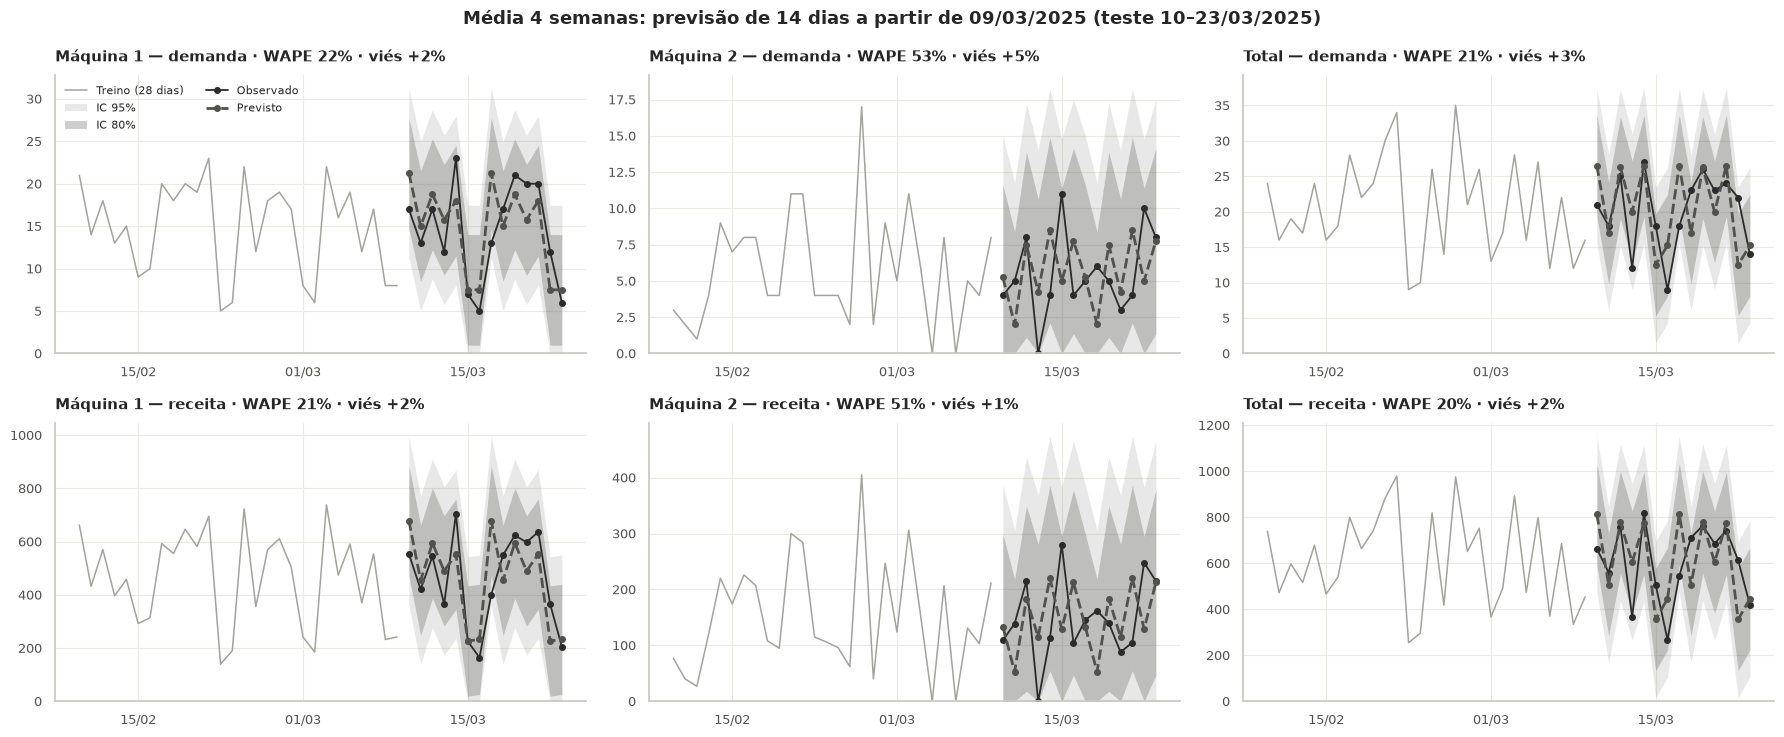

In [2]:
display(pd.concat([especificacoes(m).assign(modelo=m) for m in ['Naive sazonal', 'Média 4 semanas']]).round(2))
mostrar(painel_modelo('Média 4 semanas'))

## 2. Holt-Winters (ETS sazonal)

**Por quê:** a demanda tem padrão semanal estável dentro de cada regime, e o nível muda de forma abrupta. A suavização exponencial **adapta o nível rapidamente**, e a janela de estimação curta (hiperparâmetro) evita que regimes antigos contaminem a sazonalidade.

**Lição herdada de `modelagens_testes`:** com o treino inteiro, o AICc preferia retirar a sazonalidade. A mistura de regimes diluía o padrão semanal no ruído das quebras.

,série,alvo,especificação,início do treino,MAE validação,tempo (s)
0,Máquina 1,demanda,"ETS(A,N,M) · últimas 8 semanas · raiz (Anscombe)",13/01/2025,3.750,1.020
1,Máquina 1,receita,"ETS(A,N,A) · últimas 8 semanas · nenhuma",13/01/2025,127.210,1.230
2,Máquina 2,demanda,"ETS(A,N,A) · todo o treino · nenhuma",08/02/2025,3.690,0.090
3,Máquina 2,receita,"ETS(A,N,A) · todo o treino · nenhuma",08/02/2025,95.100,0.120
4,Total,demanda,"ETS(A,N,A) · últimas 8 semanas · nenhuma",13/01/2025,5.310,1.030
5,Total,receita,"ETS(A,N,A) · últimas 8 semanas · nenhuma",13/01/2025,159.930,1.310


**Máquina 1 — demanda: janela × transformação avaliadas nas dobras internas**

,janela,transformação,MAE validação
0,últimas 8 semanas,raiz (Anscombe),3.750
1,últimas 8 semanas,nenhuma,3.898
2,desde a última quebra,nenhuma,4.019
3,desde a última quebra,raiz (Anscombe),4.041
4,últimas 16 semanas,nenhuma,4.307
5,últimas 16 semanas,raiz (Anscombe),5.209
6,todo o treino,nenhuma,5.596
7,todo o treino,raiz (Anscombe),5.610


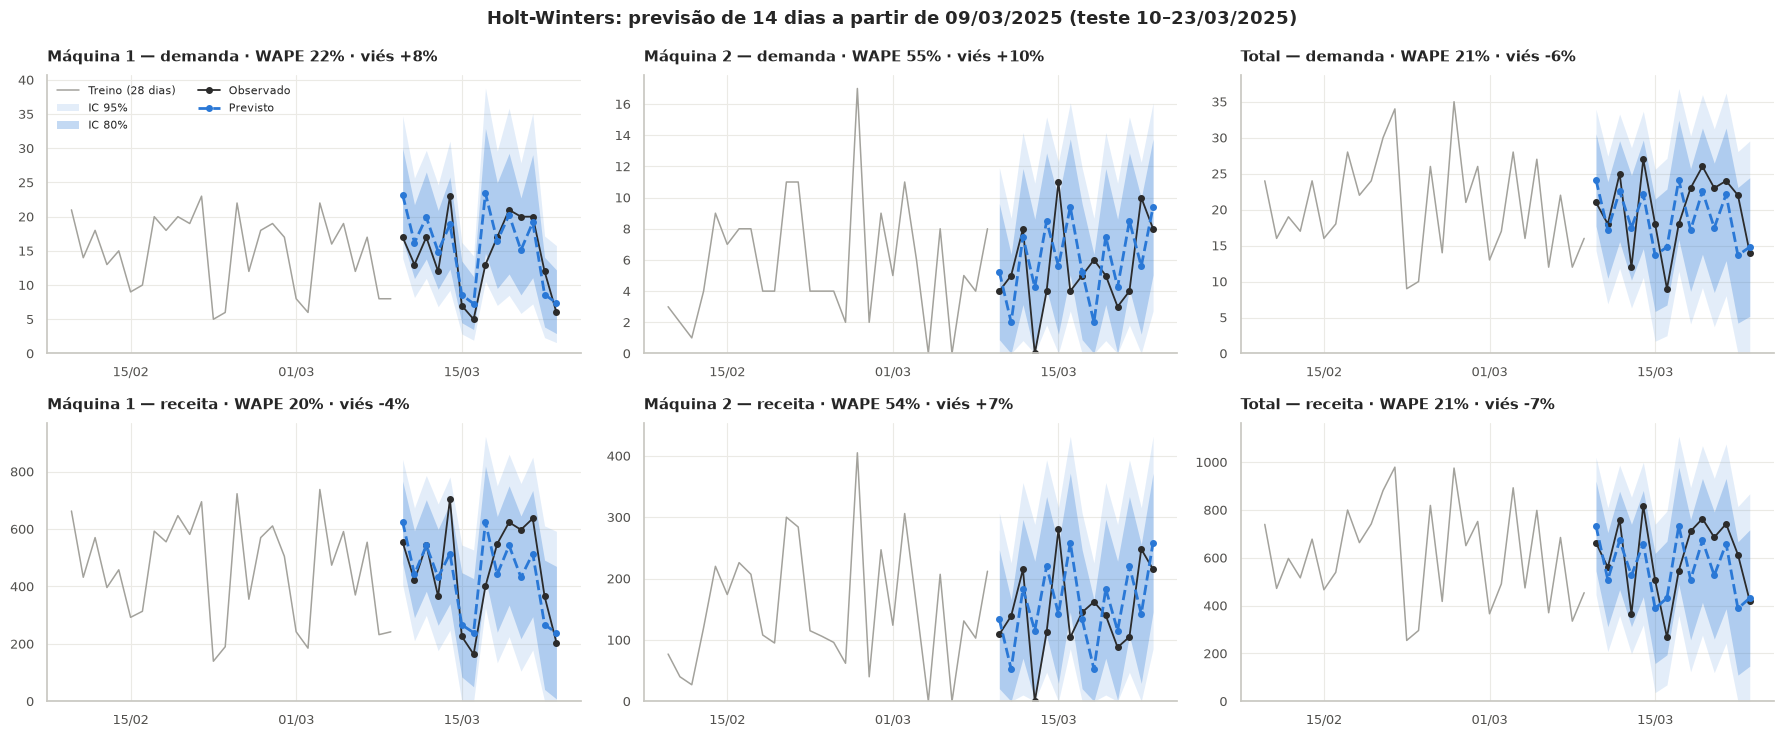

In [3]:
display(especificacoes("Holt-Winters").round(2))
display(Markdown("**Máquina 1 — demanda: janela × transformação avaliadas nas dobras internas**"))
display(R[("Holt-Winters", "Máquina 1", "demanda")].extras["candidatos"].round(3))
mostrar(painel_modelo("Holt-Winters"))

**Leitura:**
- A validação escolhe as **últimas 8 semanas** nas séries longas. Na demanda da M1, escolhe também a transformação de Anscombe com sazonalidade **multiplicativa**, ETS(A,N,M).
- Na M2 (30 dias), a sazonalidade estimada é pouco confiável.
- Os intervalos se ampliam com o horizonte, como esperado.

## 3. SARIMAX

**Por quê:** é o modelo que incorpora **explicitamente** as variáveis estruturais conhecidas na origem: dummies de quebra, `maquinas_ativas` no Total e calendário. Os erros seguem um processo SARIMA, que captura a autocorrelação restante. As exógenas são escolhidas por AICc, e o ΔAICc contra o SARIMA sem exógenas é reportado: valor positivo significa que nenhuma exógena melhora o ajuste.

,série,alvo,especificação,início do treino,MAE validação,tempo (s)
0,Máquina 1,demanda,"SARIMA(0,1,1)(1,0,1)[7] + [data_comercial, dum...",13/01/2025,4.560,9.630
1,Máquina 1,receita,"SARIMA(0,0,0)(0,1,1)[7] + [data_comercial] · d...",30/01/2025,148.290,8.880
2,Máquina 2,demanda,"SARIMA(0,0,0)(0,0,0)[7] + [data_comercial] · t...",08/02/2025,3.790,0.460
3,Máquina 2,receita,"SARIMA(0,0,0)(0,0,0)[7] + [data_comercial] · t...",08/02/2025,99.320,0.440
4,Total,demanda,"SARIMA(0,1,1)(1,0,0)[7] + [maquinas_ativas, da...",13/01/2025,6.340,4.720
5,Total,receita,"SARIMA(0,1,1)(1,0,1)[7] + [maquinas_ativas, da...",13/01/2025,182.060,8.120


**Máquina 1 — demanda: conjuntos de exógenas (AICc) e coeficientes do escolhido** · Ljung-Box p = 0.94

,conjunto,variáveis,AICc,ΔAICc vs sem exógenas
0,calendário + quebras,"data_comercial, dummy_novos_clientes",309.600,-14.280
1,completo,"data_comercial, inicio_mes, dummy_novos_clientes",311.450,-12.430
2,calendário,data_comercial,325.770,1.890


,coeficiente,erro-padrão,p-valor
data_comercial,-1.520,5.185,0.769
dummy_novos_clientes,8.735,0.868,0.000


**Total — demanda: conjuntos de exógenas (AICc) e coeficientes do escolhido** · Ljung-Box p = 0.82

,conjunto,variáveis,AICc,ΔAICc vs sem exógenas
0,completo,"maquinas_ativas, data_comercial, inicio_mes, d...",359.640,0.420
1,calendário + quebras,"maquinas_ativas, data_comercial, dummy_novos_c...",362.270,3.060
2,calendário,"maquinas_ativas, data_comercial",363.030,3.820


,coeficiente,erro-padrão,p-valor
maquinas_ativas,5.907,4.286,0.168
data_comercial,-2.239,4.548,0.623
inicio_mes,4.035,1.980,0.042
dummy_novos_clientes,6.052,3.072,0.049


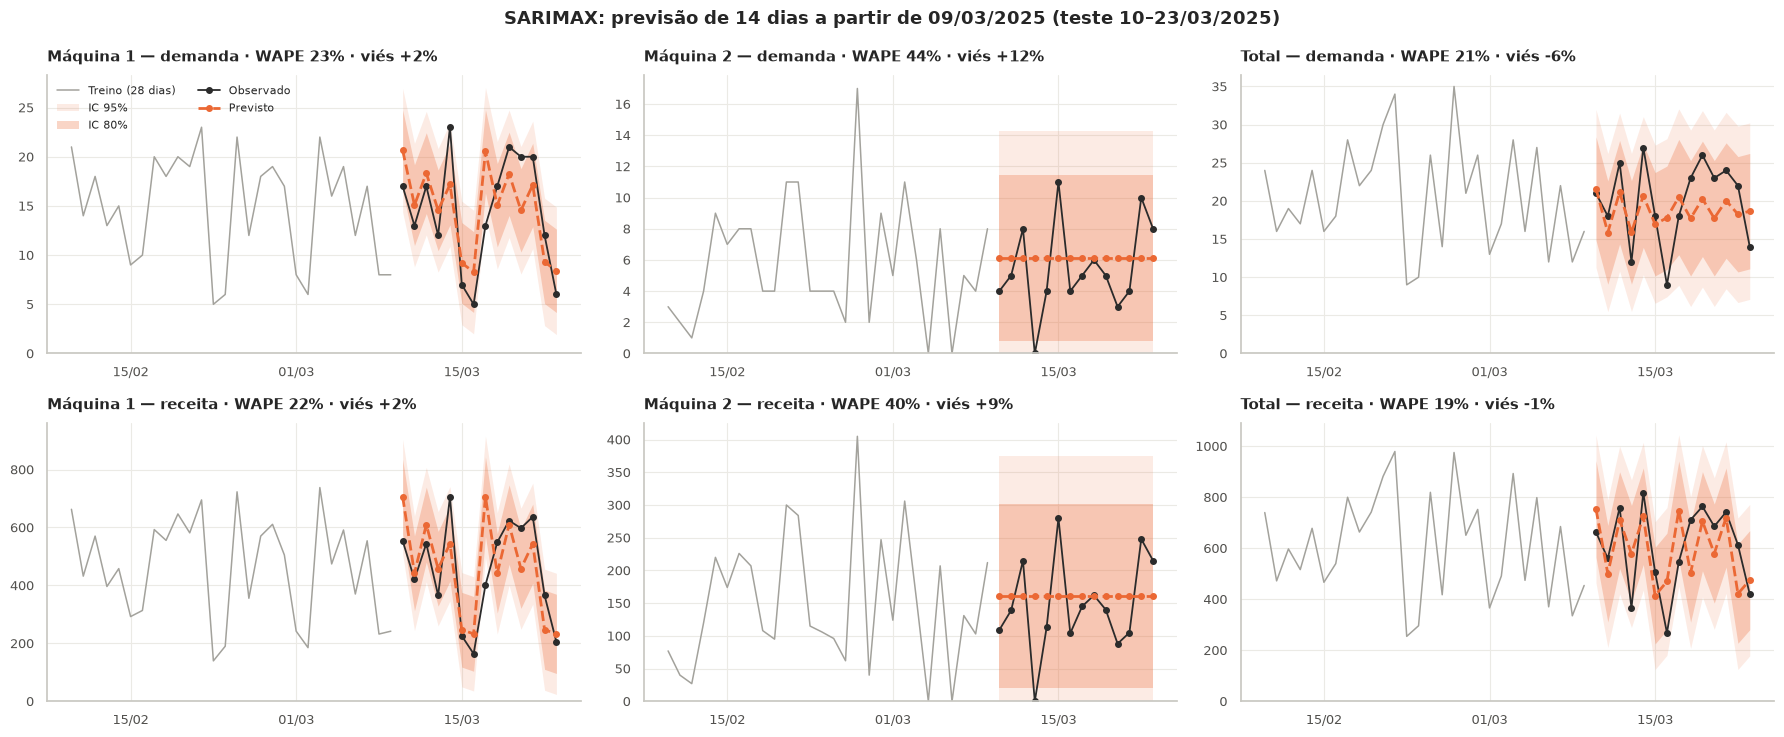

In [4]:
display(especificacoes("SARIMAX").round(2))
for s, a in [("Máquina 1", "demanda"), ("Total", "demanda")]:
    r = R[("SARIMAX", s, a)]
    display(Markdown(f"**{s} — {a}: conjuntos de exógenas (AICc) e coeficientes do escolhido** · Ljung-Box p = {r.extras['Ljung-Box p']:.2f}"))
    display(r.extras["exogenas"].round(2))
    display(r.extras["coeficientes"].round(4))
mostrar(painel_modelo("SARIMAX"))

**Leitura:**
- **Na M1**, a janela de 8 semanas inclui a quebra de 30/01, e `dummy_novos_clientes` entra com efeito grande e significativo. No Total, entram `maquinas_ativas` e `dummy_novos_clientes`.
- `dummy_horario_reduzido` é constante nas janelas curtas e sai automaticamente. Seu valor aparece nos modelos estimados com janelas longas e na análise de contribuição (notebook 04).
- O Ljung-Box não rejeita a ausência de autocorrelação residual.

## 4. Modelo de contagem (Poisson / Binomial Negativa)

**Por quê:** a demanda é uma contagem pequena, com variância que cresce com a média. Um modelo de contagem com ligação log produz intervalos assimétricos e nunca negativos. Ele também responde se há sobredispersão **dentro** do regime, por razão de verossimilhança α = 0 com correção de fronteira.

**Receita:** cada trajetória de demanda simulada recebe tickets sorteados dos últimos 28 dias (Poisson composto). É uma previsão de receita coerente com o volume e com a tabela de preços vigente.

,série,alvo,especificação,início do treino,MAE validação,tempo (s)
0,Máquina 1,demanda,Poisson [+ dia da semana] · desde a última quebra,30/01/2025,4.870,0.500
1,Máquina 1,receita,Poisson [+ dia da semana] · desde a última que...,30/01/2025,149.780,0.110
2,Máquina 2,demanda,NB2 [nível + exógenas] · todo o treino,15/02/2025,3.710,0.060
3,Máquina 2,receita,NB2 [nível + exógenas] · todo o treino · recei...,15/02/2025,98.220,0.030
4,Total,demanda,Poisson [+ dia da semana] · desde a última quebra,04/02/2025,5.570,0.530
5,Total,receita,Poisson [+ dia da semana] · desde a última que...,04/02/2025,162.140,0.110


**Máquina 1 — demanda** · α (NB2) = 0.0000 · p(α = 0) = 0.500

,especificação,família,AIC
0,+ dia da semana,Poisson,204.340
1,+ dia da semana + dinâmica,Poisson,208.750
2,+ dinâmica,Poisson,229.040
3,+ dinâmica,NB2,230.440
4,nível + exógenas,NB2,248.260
5,nível + exógenas,Poisson,262.760


,coeficiente,erro-padrão,p-valor
const,3.091,0.095,0.000
dow_ter,-0.424,0.152,0.005
dow_qua,-0.105,0.139,0.447
dow_qui,-0.452,0.145,0.002
dow_sex,-0.278,0.138,0.044
dow_sab,-0.991,0.172,0.000
dow_dom,-1.054,0.176,0.000


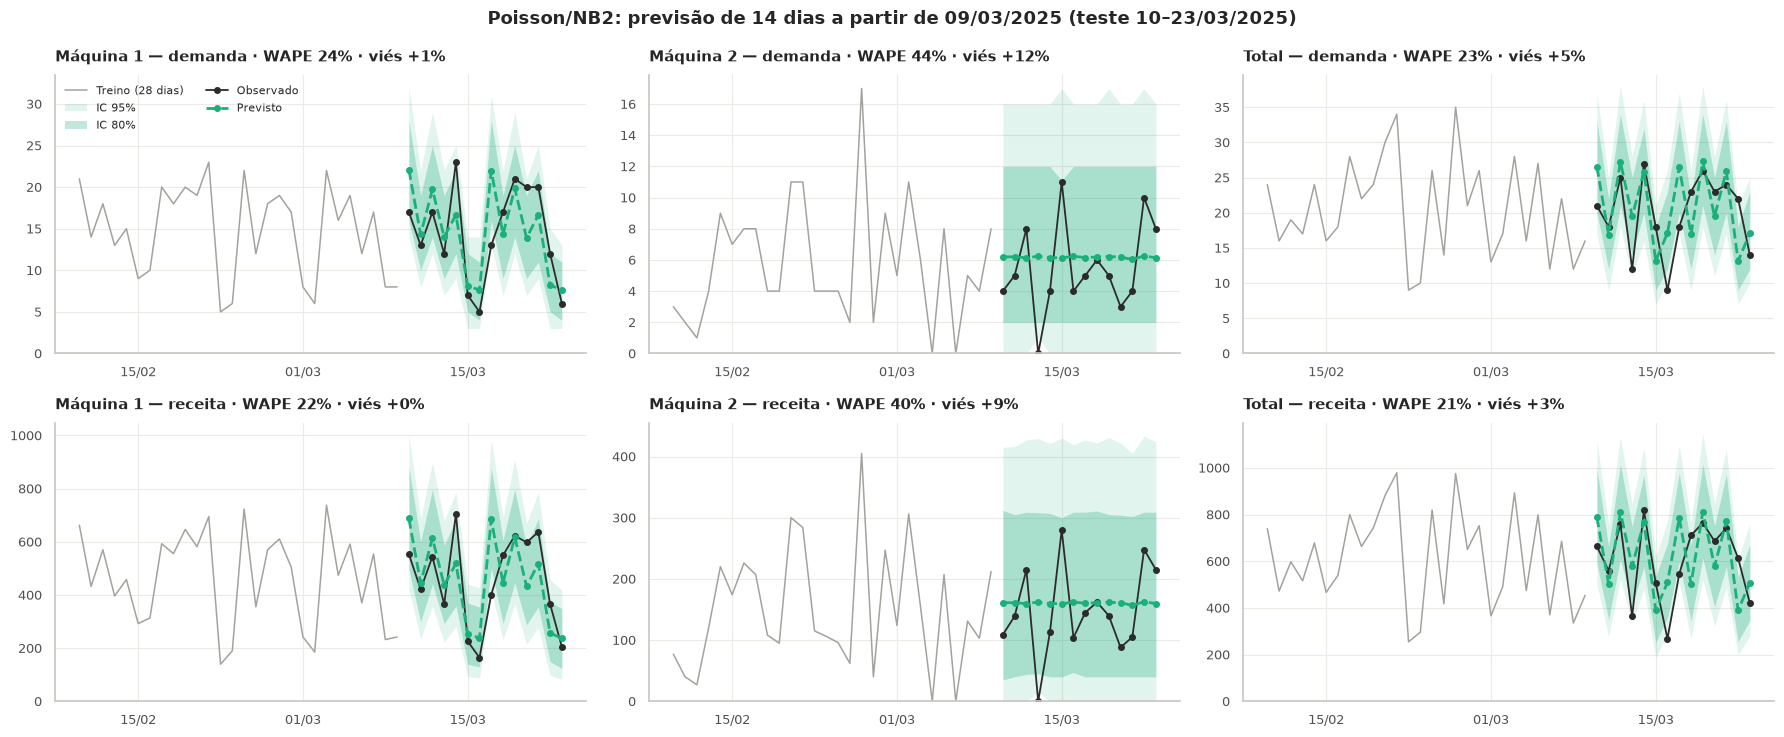

In [5]:
display(especificacoes("Poisson/NB2").round(2))
r = R[("Poisson/NB2", "Máquina 1", "demanda")]
display(Markdown(f"**Máquina 1 — demanda** · α (NB2) = {r.extras['α (NB2)']:.4f} · p(α = 0) = {r.extras['p (α = 0)']:.3f}"))
display(r.extras["tabela"].round(2))
display(r.extras["coeficientes"].round(4))
mostrar(painel_modelo("Poisson/NB2"))

**Leitura:**
- Na M1, a escolha é **Poisson com dia da semana**, estimada desde a última quebra. Quando o dia da semana entra, a NB2 converge para α → 0: **dentro do regime atual não há sobredispersão**. A "variância extra" da série inteira vinha de mudanças de nível.
- Os coeficientes de sábado e domingo indicam ~60% menos vendas no fim de semana da M1.

## 5. Random Forest

**Por quê:** captura não linearidades e interações entre defasagens, janelas móveis, calendário e dummies, sem supor uma forma funcional. A previsão de 14 dias é **recursiva**.

**Seleção (sempre nas dobras internas, com a mesma recursão do teste):**
1. profundidade, folha mínima e fração de atributos;
2. meia-vida dos pesos de recência e inclusão dos atributos comportamentais.

Em cada estágio vale a **regra de 1 erro-padrão**: escolhe-se a configuração menos complexa a até 1 EP da melhor. A regra foi decidida no backtest de 10 origens **anteriores ao teste**, em que empatou com a escolha pelo mínimo (MASE 0,862 × 0,868). Ela protege a M2, que tem uma só dobra de validação.

**Intervalos conformais:** vêm de |erro| das dobras posteriores à última quebra. **Ajuste no treino:** previsões de 1 passo fora da amostra, reestimando a cada 28 dias.

,série,alvo,especificação,início do treino,MAE validação,tempo (s)
0,Máquina 1,demanda,"max_depth=8, min_samples_leaf=5, max_features=...",01/03/2024,5.080,32.220
1,Máquina 1,receita,"max_depth=8, min_samples_leaf=5, max_features=...",01/03/2024,151.010,30.600
2,Máquina 2,demanda,"max_depth=8, min_samples_leaf=5, max_features=...",08/02/2025,3.580,9.200
3,Máquina 2,receita,"max_depth=8, min_samples_leaf=5, max_features=...",08/02/2025,95.120,9.230
4,Total,demanda,"max_depth=8, min_samples_leaf=5, max_features=...",01/03/2024,7.180,30.580
5,Total,receita,"max_depth=8, min_samples_leaf=5, max_features=...",01/03/2024,206.800,34.970


**Máquina 1 — demanda: grade avaliada (WAPE de validação, EP e complexidade)**

,estágio,configuração,WAPE validação %,EP do WAPE,complexidade,escolhida
0,2,"max_depth=8, min_samples_leaf=5, max_features=...",33.610,4.890,2,False
1,2,"max_depth=8, min_samples_leaf=5, max_features=...",34.300,4.760,1,False
2,1,"max_depth=None, min_samples_leaf=1, max_featur...",34.730,4.590,3,False
3,2,"max_depth=8, min_samples_leaf=5, max_features=...",35.240,5.020,2,False
4,2,"max_depth=8, min_samples_leaf=5, max_features=...",35.250,5.050,1,False
5,1,"max_depth=None, min_samples_leaf=1, max_featur...",35.430,4.690,4,False
6,1,"max_depth=8, min_samples_leaf=1, max_features=...",35.590,4.660,3,False
7,2,"max_depth=8, min_samples_leaf=5, max_features=...",35.690,4.770,2,False
8,2,"max_depth=8, min_samples_leaf=5, max_features=...",35.820,4.720,1,False
9,1,"max_depth=8, min_samples_leaf=1, max_features=...",36.120,4.580,2,False


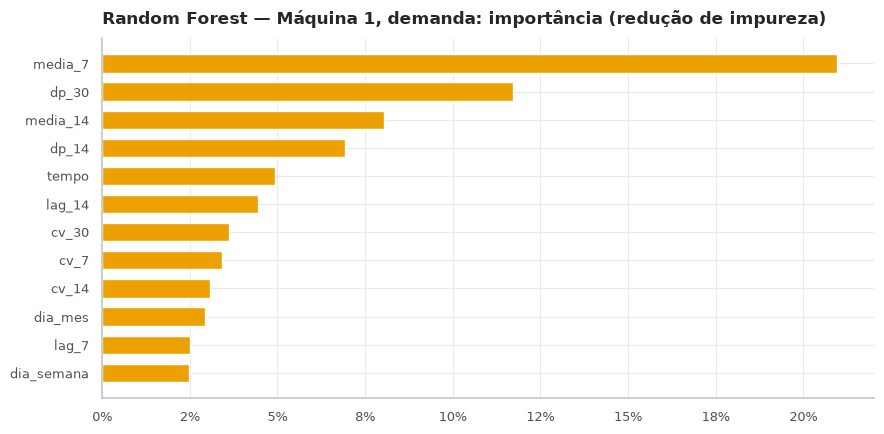

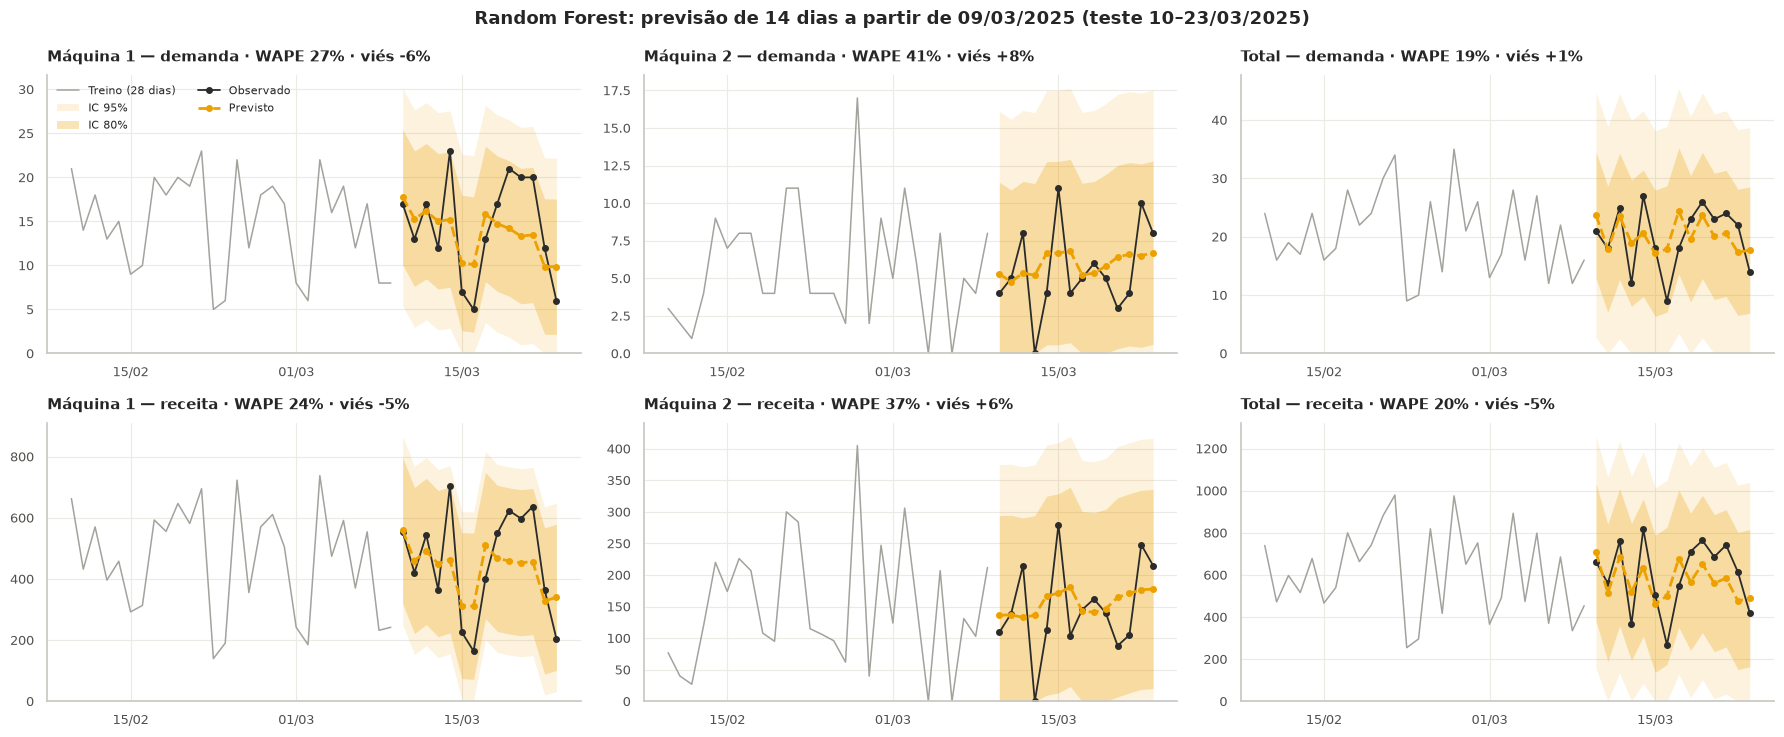

In [6]:
display(especificacoes("Random Forest").round(2))
r = R[("Random Forest", "Máquina 1", "demanda")]
display(Markdown("**Máquina 1 — demanda: grade avaliada (WAPE de validação, EP e complexidade)**"))
display(r.extras["grade"].round(2))
imp = r.extras["importancias"].head(12)[::-1]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(imp.index, imp.values, color=CORES_MODELOS["Random Forest"], height=0.65)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Random Forest — Máquina 1, demanda: importância (redução de impureza)")
fig.tight_layout()
mostrar(fig)
mostrar(painel_modelo("Random Forest"))

**Leitura:**
- A regra de 1 EP escolhe a floresta **regularizada** (profundidade 8, folha ≥ 5, 50% dos atributos, sem pesos de recência e sem comportamentais). As diferenças de validação entre configurações ficam dentro do ruído.
- As médias móveis recentes dominam a importância, coerente com a importância por permutação do notebook 04.
- **Limitação estrutural:** árvores não extrapolam. Um novo patamar só é capturado pelas médias móveis, com atraso.

## 6. Visão comparativa no teste (detalhes e significância no notebook 07)

In [7]:
cols = ["modelo", "série", "alvo", "MAE", "RMSE", "WAPE_%", "MAPE_%", "ME", "MASE", "cobertura_80_%", "cobertura_95_%", "MAE validação"]
display(tab[cols].sort_values(["série", "alvo", "MAE"]).round(2).reset_index(drop=True))

,modelo,série,alvo,MAE,RMSE,WAPE_%,MAPE_%,ME,MASE,cobertura_80_%,cobertura_95_%,MAE validação
0,Média 4 semanas,Máquina 1,demanda,3.180,3.710,21.920,24.320,0.320,0.690,92.860,100.000,4.550
1,Holt-Winters,Máquina 1,demanda,3.240,4.120,22.350,25.360,1.160,0.700,92.860,100.000,3.750
2,SARIMAX,Máquina 1,demanda,3.330,3.730,22.930,26.820,0.260,0.720,78.570,92.860,4.560
3,Poisson/NB2,Máquina 1,demanda,3.490,4.160,24.060,26.050,0.150,0.760,78.570,100.000,4.870
4,Naive sazonal,Máquina 1,demanda,3.500,4.330,24.140,26.490,0.070,0.760,100.000,100.000,4.600
5,Random Forest,Máquina 1,demanda,3.870,4.470,26.690,32.180,-0.850,0.840,92.860,100.000,5.080
6,Holt-Winters,Máquina 1,receita,92.730,111.680,20.420,21.840,-16.770,0.630,85.710,100.000,127.210
7,Média 4 semanas,Máquina 1,receita,93.890,115.960,20.680,22.250,7.290,0.630,92.860,100.000,146.120
8,SARIMAX,Máquina 1,receita,99.110,124.040,21.830,23.270,8.600,0.670,71.430,92.860,148.290
9,Poisson/NB2,Máquina 1,receita,100.230,123.760,22.070,23.410,1.820,0.680,78.570,92.860,149.780


## 7. Justificativa, alternativas e trade-offs

| Modelo | Vantagens | Limitações | Quando preferir |
|---|---|---|---|
| Holt-Winters | adapta o nível rápido; intervalos analíticos; barato e interpretável | sem exógenas; pequena oscilação numérica do otimizador | séries longas com padrão semanal estável dentro do regime |
| SARIMAX | incorpora quebras e máquinas ativas; coeficientes testáveis | ordens instáveis perto das quebras | quando os eventos estruturais são conhecidos (Total) |
| Poisson/NB2 | distribuição correta para contagens; intervalos bem calibrados | supõe que o regime persiste; a receita depende da tabela de preços recente | intervalos para estoque de segurança |
| Random Forest | não linearidades; robusta | não extrapola; precisa de histórico; mais cara | quando há histórico e relações não lineares |

**Descartados com evidência** (`modelagens_testes.ipynb`): Croston/SBA/TSB (a demanda não é intermitente), GARCH (heterocedasticidade de nível), TBATS, Prophet, Theta, XGBoost/LightGBM/CatBoost (menos estáveis em 11 origens), modelo conjunto M1 + M2 (piora a M2 em 46% a 90%) e NHITS/NBEATSx (memorizam o ruído). O *ensemble* SARIMA + XGBoost foi bom nas origens, mas é uma combinação; combinações ficam como evolução futura (`docs/limitations.md`).